<a href="https://colab.research.google.com/github/ipr2104/Advanced-Quant/blob/main/HW3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Homework 3**

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm

The data file "WUS_afab.csv" is available in Coursework. Using the predictors you selected in Question 3, fit a linear regression model of log(burned area) to the first 27
years of data (1984–2010).

(a) Write down the fitted equation and report the training R² and RMSE. (10%)

(b) Discuss the importance of each predictor. Quantify its effect as the change in burned
area for a one-standard-deviation increase in that predictor, and compare the predictors. (10%)

(c) Use the model to predict the last 10 years (2011–2020). Report the testing RMSE of
log (burned area), r2, and plot the observed and predicted burned area as a time series. (10%)

(d) Compare your testing RMSE from (c) with the LOOCV RMSE of your selected model shown in the figure. Is it larger or smaller? Why might the error on a single, later 10- year period differ from the LOOCV estimate obtained within the training years? (5%)

In [2]:
# Western US burned area
df = pd.read_csv('WUS_afab.csv')

In [9]:
# Burned area
y = df['afab_km2'].to_numpy()
# Log of burned area
log_y = np.log(y)

n = len(y)

In [10]:
# Split training and testing
predictors = ['vpd_hPa', 'wind_ms', 'temp_C']
train = np.arange(27)
test = np.arange(27, n)

In [17]:
# Standardize the predictors
# Mean and sd from training
vpd_mean = df['vpd_hPa'].iloc[train].mean()
vpd_sd = df['vpd_hPa'].iloc[train].std(ddof = 1)

wind_mean = df['wind_ms'].iloc[train].mean()
wind_sd = df['wind_ms'].iloc[train].std(ddof = 1)

temp_mean = df['temp_C'].iloc[train].mean()
temp_sd = df['temp_C'].iloc[train].std(ddof = 1)

In [19]:
# Standardize training predictors
z_vpd_training = (df['vpd_hPa'].iloc[train] - vpd_mean) / vpd_sd
z_wind_training = (df['wind_ms'].iloc[train] - wind_mean) / wind_sd
z_temp_training = (df['temp_C'].iloc[train] - temp_mean) / temp_sd

# Standardize testing
z_vpd_testing = (df['vpd_hPa'].iloc[test] - vpd_mean) / vpd_sd
z_wind_testing = (df['wind_ms'].iloc[test] - wind_mean) / wind
z_temp_testing = (df['temp_C'].iloc[test] - temp_mean) / temp_sd

In [26]:
# Fitting the model 5a
# Training predictor df
X = pd.DataFrame({
    'vpd_hPa': z_vpd_training,
    'wind_ms': z_wind_training,
    'temp_C': z_temp_training
})

# Intercept
X = sm.add_constant(X)

# Fir regression to training
y_training = log_y[train]
m3 = sm.OLS(y_training, X).fit()
m3.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.944
Model:                            OLS   Adj. R-squared:                  0.936
Method:                 Least Squares   F-statistic:                     128.2
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           1.69e-14
Time:                        16:20:58   Log-Likelihood:                 3.5023
No. Observations:                  27   AIC:                            0.9953
Df Residuals:                      23   BIC:                             6.179
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.8529      0.044    177.201      0.000       7.761       7.945
vpd_hPa        0.5987      0.064      9.367      0.000       0.467       0.731
wind_ms        0.4078      0.047      8.678      0.000       0.311       0.505
temp_C         0.1203      0.062      1.935      0.065      -0.008       0.249
==============================================================================
Omnibus:                        3.362   Durbin-Watson:                   1.735
Prob(Omnibus):                  0.186   Jarque-Bera (JB):                2.213
Skew:                           0.693   Prob(JB):                        0.331
Kurtosis:                       3.209   Cond. No.                         2.44
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

log burned area = 7.853 + 0.599zvpd + 0.408zwind + 0.120ztemp

Training R^2 is 0.944 --> the model explains 94.4% of variation in log burned area over the 27 years.

RMSE of 0.213.

In [31]:
# Training RMSE
y_training_fit = m3.predict(X)
train_rmse = np.sqrt(np.mean((y_training - y_training_fit)**2))
print(f'Training RMSE: {train_rmse}')

Training RMSE: 0.21253370844482442


In [37]:
# Approximating change in burned area
print(100 * (np.exp(0.5987) - 1))
print(100 * (np.exp(0.408) - 1))
print(100 * (np.exp(0.120) - 1))

81.97515849734052
50.38071611701118
12.749685157937574


In [44]:
# Predict last 10 years 5c
X_test = pd.DataFrame({
    'vpd_hPa': z_vpd_testing,
    'wind_ms': z_wind_testing,
    'temp_C': z_temp_testing})

X_test = sm.add_constant(X_test)

# Observed log burned for testing years
y_testing = log_y[test]

# Predict log burned
y_test_predict = m3.predict(X_test)

# Testing RMSE
test_rmse = np.sqrt(np.mean((y_testing - y_test_predict)**2))
print(f'Testing RMSE: {test_rmse}')

# Testing R^2
test_r2 = np.corrcoef(y_testing, y_test_predict)[0, 1]**2
print(f'Testing R^2: {test_r2}')

Testing RMSE: 0.2467177645133835
Testing R^2: 0.8806567573482976


<module 'matplotlib.pyplot' from '/usr/local/lib/python3.13/dist-packages/matplotlib/pyplot.py'>

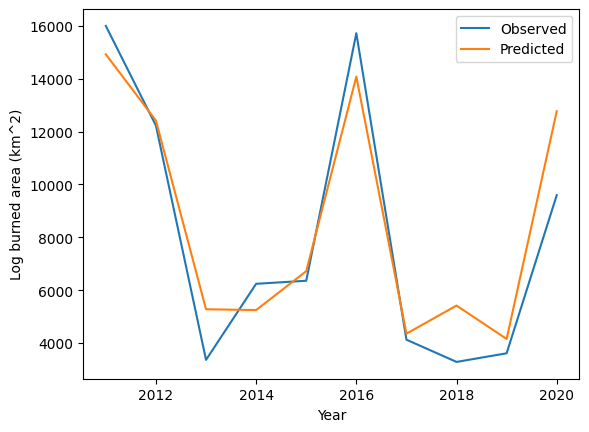

In [45]:
# Plot observed and predicted burned area
plt.plot(df['year'].iloc[test], np.exp(y_testing), label = 'Observed')
plt.plot(df['year'].iloc[test], np.exp(y_test_predict), label = 'Predicted')
plt.xlabel('Year')
plt.ylabel('Log burned area (km^2)')
plt.legend()
plt

Potential intensity (PI) measures how favorable the thermodynamic
environment is for tropical cyclones: it is the theoretical maximum intensity a storm can reach under given ocean and atmospheric conditions. The file “PI_DA_input.csv” contains annual PI anomalies (m/s, relative to 1976–
2005) for the Northern Hemisphere (NH, June–November) (6-9, 45%)

▪ NH_obs_proxy: the "observed" PI, 1850–2005. This is one model realization used as a proxy for observations

▪ NH_GHG: the simulated PI response to greenhouse-gas forcing only (ensemble mean)

▪ NH_aerosols: the simulated PI response to anthropogenic aerosol forcing only (ensemble mean)

▪ NH_hist_aer: the simulated PI response to all historical forcings except aerosols (ensemble mean)

▪ NH_control: PI anomalies from a 500-year control simulation without changes in external forcing

▪ Note that The first four columns cover 1850–2005 (rows 1–156). The control simulation is longer, so rows 157–500 contain only the control columns.

6. Scaling factors. Estimate the scaling factors for the greenhouse-gas (GHG), aerosol (AER)
and natural (NAT) forcings, with their 95% confidence intervals, using the full period
1850–2005:

(a) No natural-only simulation is provided. Explain how you obtain the natural response
from the available data, and plot the PI response to natural forcing. (7 %)

(b) Fill in the table below with the scaling factors and their 95% confidence intervals,
accounting for serial correlation in the noise using the control simulation. (13%)

7. Detection and attribution. For each forcing, state whether its signal is detected and
whether it is attributed. Fill in the table below. Justify your answer. (5%)

8. Attributable change. For each forcing, estimate the change in PI attributable to it over
1850–2005 and over 1950–2005. Compute the change in a forced response as its linear
trend multiplied by the number of years in the period. Fill in the table below. (10%)

9. Discussion. Discuss your results in Question 8. How does the sum of the attributable
changes compare with the observed change from NH_obs_proxy? What does this tell
you about the roles of GHG and aerosol forcing in NH potential intensity? (10%)


In [46]:
# Data
d = pd.read_csv("NH_PI_DA_input.csv")
reg = d.dropna(subset=["year"]).copy()        # 1850-2005 (156 years)
control = d["NH_control"].dropna()            # 500-year control run

# Natural response: hist_aer = GHG + NAT  ->  NAT = hist_aer - GHG
reg["GHG"] = reg["NH_GHG"]
reg["AER"] = reg["NH_aerosols"]
reg["NAT"] = reg["NH_hist_aer"] - reg["NH_GHG"]
obs = reg["NH_obs_proxy"]
reg

,year,NH_obs_proxy,NH_GHG,NH_aerosols,NH_hist_aer,NH_control,GHG,AER,NAT
0,1850.0,-0.3579,-1.1447,1.3348,-1.0064,0.2934,-1.1447,1.3348,0.1383
1,1851.0,-0.1012,-1.0953,1.2948,-0.9675,0.3427,-1.0953,1.2948,0.1278
2,1852.0,0.1311,-1.1265,1.4013,-1.0611,0.2626,-1.1265,1.4013,0.0654
3,1853.0,-0.0063,-1.1401,1.2309,-1.1331,0.2031,-1.1401,1.2309,0.0070
4,1854.0,0.1907,-1.1774,1.2162,-1.2177,0.7088,-1.1774,1.2162,-0.0403
...,...,...,...,...,...,...,...,...,...
151,2001.0,-0.0793,0.2444,-0.1167,0.3485,-0.1346,0.2444,-0.1167,0.1041
152,2002.0,-0.1745,0.2282,-0.1588,0.4495,-0.2829,0.2282,-0.1588,0.2213
153,2003.0,0.0187,0.3191,-0.3008,0.4545,-0.2824,0.3191,-0.3008,0.1354
154,2004.0,0.1140,0.3622,-0.3270,0.5001,0.0381,0.3622,-0.3270,0.1379


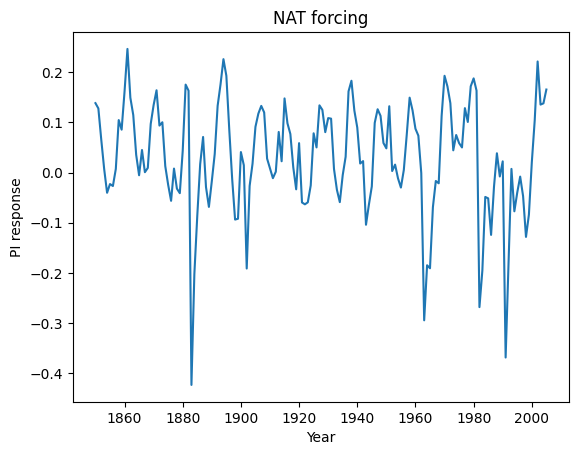

In [49]:
# Plot Nat forcing
plt.plot(reg["year"],reg["NAT"])
plt.title('NAT forcing')
plt.ylabel('PI response')
plt.xlabel("Year")
plt.savefig('PI_NA.png')


In [50]:
# Fit the OLS
X = sm.add_constant(reg[["GHG", "AER", "NAT"]])
y = obs
m4 = sm.OLS(y, X).fit()
m4.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:           NH_obs_proxy   R-squared:                       0.125
Model:                            OLS   Adj. R-squared:                  0.108
Method:                 Least Squares   F-statistic:                     7.243
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           0.000142
Time:                        17:39:14   Log-Likelihood:                -39.393
No. Observations:                 156   AIC:                             86.79
Df Residuals:                     152   BIC:                             98.99
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0241      0.050     -0.485      0.628      -0.122       0.074
GHG            0.5849      0.168      3.479      0.001       0.253       0.917
AER            0.5801      0.148      3.914      0.000       0.287       0.873
NAT            0.5337      0.232      2.303      0.023       0.076       0.992
==============================================================================
Omnibus:                        0.415   Durbin-Watson:                   0.824
Prob(Omnibus):                  0.813   Jarque-Bera (JB):                0.475
Skew:                           0.120   Prob(JB):                        0.789
Kurtosis:                       2.877   Cond. No.                         14.5
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [63]:
from statsmodels.tsa.stattools import acf

# Effective sample size from the control run
n, p = len(obs), len(m4.params)

r1 = acf(control, nlags = 1)[1]
n_eff = n * (1 - r1) / (1 + r1)
t = stats.t.ppf(0.975, n_eff - p)

print(f'Lag 1 autocorrelation:{r1}')
print(f'Effective sample size: {n_eff}')

Lag 1 autocorrelation:0.47981391073243285
Effective sample size: 54.83732065038895


In [64]:
# Corrected standard errors and t critical value
beta = m4.params.drop("const")
se = m4.bse.drop("const") * np.sqrt(n / n_eff)

In [70]:
# CI low and high
CI_high = beta + t * se
CI_low = beta - t * se

print(f'CI high: {CI_high}')
print(f'CI low: {CI_low}')

CI high: GHG    1.154232
AER    1.082018
NAT    1.318453
dtype: float64
CI low: GHG    0.015570
AER    0.078223
NAT   -0.251074
dtype: float64


In [73]:
# Table
scaling_table = pd.DataFrame({
    'Scaling factor': beta,
    '95% CI low': CI_low,
    '95% CI high': CI_high
})
scaling_table.index = ["GHG", "AER", "NAT"]
scaling_table

,Scaling factor,95% CI low,95% CI high
GHG,0.584901,0.015570,1.154232
AER,0.580120,0.078223,1.082018
NAT,0.533689,-0.251074,1.318453


In [90]:
# Attributable change (fit data with year)
## for 1850-2005
period = reg[(reg["year"] >= 1850) & (reg["year"] <= 2005)]

print("1850 - 2005")
for forcing in ['GHG', 'AER', 'NAT']:
  slope, intercept = np.polyfit(period["year"], period[forcing], 1)
  change = beta[forcing] * slope * (2005 - 1850)
  print(forcing, "trend =", slope, "attributable change =", change)

1850 - 2005
GHG trend = 0.009038666055538862 attributable change = 0.8194420510799316
AER trend = -0.010228762150116156 attributable change = -0.9197563607690991
NAT trend = -0.0002806220859477501 attributable change = -0.023213584162760342


In [91]:
# Observed change
slope_obs, intercept_obs = np.polyfit(period["year"], period["NH_obs_proxy"], 1)
print("Observed change =", slope_obs*155)

Observed change = -0.15111582557569697


In [92]:
# For 1950-2005
period = reg[(reg["year"] >= 1950) & (reg["year"] <= 2005)]

print("1950 - 2005")
for forcing in ['GHG', 'AER', 'NAT']:
  slope, intercept = np.polyfit(period["year"], period[forcing], 1)
  change = beta[forcing] * slope * (2005 - 1950)
  print(forcing, "trend =", slope, "attributable change =", change)

1950 - 2005
GHG trend = 0.020674839371155083 attributable change = 0.6651001426873984
AER trend = -0.017485758714969196 attributable change = -0.5579113446722859
NAT trend = -0.00040447368421051905 attributable change = -0.011872484577193325


In [93]:
# Observed change
slope_obs, intercept_obs = np.polyfit(period["year"], period["NH_obs_proxy"], 1)
print("Observed change =", slope_obs*55)

Observed change = 0.18094793233082515
